Company Data Analysis Project - WEBSCRAPPING + EDA

1. Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


2. Loading the Datase

In [2]:
df = pd.read_csv("Companies.csv")

To DISPLAY ALL ROWS

In [3]:
#pd.set_option('display.max_rows', None)  TO see all rows
# pd.reset_option('display.max_rows')   TO see few rows

In [4]:
df

,Rank,Name,Industry,Revenue (USD millions),Revenue growth,Employees,Headquarters
0,1,Walmart,Retail,"680,985",5.1%,"2,100,000","Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,"637,959",11.0%,"1,556,000","Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,"400,278",7.7%,"400,000","Minnetonka, Minnesota"
3,4,Apple,Technology,"391,035",2.0%,"164,000","Cupertino, California"
4,5,CVS Health,Healthcare,"372,809",4.2%,"259,500","Woonsocket, Rhode Island"
...,...,...,...,...,...,...,...
95,96,General Dynamics,Aerospace and defense,"47,716",12.9%,"117,000","Reston, Virginia"
96,97,Coca-Cola,Beverage,"47,061",2.9%,"69,700","Atlanta, Georgia"
97,98,TIAA,Financials,"46,946",2.6%,"15,623","New York City, New York"
98,99,Travelers,Insurance,"46,423",12.2%,"34,000","New York City, New York"


3. Understanding the Dataset

In [5]:
df.shape

(100, 7)

In [6]:
df.columns

Index(['Rank', 'Name', 'Industry', 'Revenue (USD millions)', 'Revenue growth',
       'Employees', 'Headquarters'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Rank                    100 non-null    int64 
 1   Name                    100 non-null    object
 2   Industry                100 non-null    object
 3   Revenue (USD millions)  100 non-null    object
 4   Revenue growth          100 non-null    object
 5   Employees               100 non-null    object
 6   Headquarters            100 non-null    object
dtypes: int64(1), object(6)
memory usage: 5.6+ KB


In [8]:
df.describe()

,Rank
count,100.000000
mean,50.500000
std,29.011492
min,1.000000
25%,25.750000
50%,50.500000
75%,75.250000
max,100.000000


In [9]:
df.describe(include='all')

,Rank,Name,Industry,Revenue (USD millions),Revenue growth,Employees,Headquarters
count,100.000000,100,100,100,100,100,100
unique,NaN,100,30,100,87,99,70
top,NaN,Walmart,Financials,"680,985",6.2%,"108,000","New York City, New York"
freq,NaN,1,16,1,3,2,13
mean,50.500000,NaN,NaN,NaN,NaN,NaN,NaN
std,29.011492,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,25.750000,NaN,NaN,NaN,NaN,NaN,NaN
50%,50.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,75.250000,NaN,NaN,NaN,NaN,NaN,NaN


4. Data Cleaning

In [10]:
# Check NULL AND DUPLICATE
df.isnull().sum()

Rank                      0
Name                      0
Industry                  0
Revenue (USD millions)    0
Revenue growth            0
Employees                 0
Headquarters              0
dtype: int64

In [11]:
df.dtypes

Rank                       int64
Name                      object
Industry                  object
Revenue (USD millions)    object
Revenue growth            object
Employees                 object
Headquarters              object
dtype: object

In [12]:
# Removing , from numerical data
df['Revenue (USD millions)']=df['Revenue (USD millions)'].str.replace(',','', regex= False)
df['Employees']=df['Employees'].str.replace(',','', regex=False)

In [13]:
# Removing % Symbol From Growth Column
df['Revenue growth']=df['Revenue growth'].str.replace('%','', regex= False)

In [14]:
# Converting Object Type to Numeric Type
df["Revenue (USD millions)"]= pd.to_numeric(df["Revenue (USD millions)"])
df["Employees"]= pd.to_numeric(df["Employees"])
df["Revenue growth"]= pd.to_numeric(df["Revenue growth"])

In [15]:
df.dtypes

Rank                        int64
Name                       object
Industry                   object
Revenue (USD millions)      int64
Revenue growth            float64
Employees                   int64
Headquarters               object
dtype: object

In [16]:
# Removing whitespaces
df["Name"] = df["Name"].str.strip()
df["Industry"] = df["Industry"].str.strip()
df["Headquarters"] = df["Headquarters"].str.strip()

In [17]:
# Changing Currency USD --> INR
Exchange_Rate = 94.59
df['Revenue (INR Crores)'] = (df['Revenue (USD millions)']*Exchange_Rate/10)

In [18]:
# DROP column
df.drop('Revenue (USD millions)',axis = 1,inplace=True)

5. Feature Engineering

In [19]:
# REVENUE PER EMPLOYEES
df["Revenue per Employee INR"] = (df['Revenue (INR Crores)']* 10000000) /df['Employees']

In [20]:
# to see numbers in below format
pd.set_option('display.float_format', '{:,.2f}'.format)

In [21]:
df

,Rank,Name,Industry,Revenue growth,Employees,Headquarters,Revenue (INR Crores),Revenue per Employee INR
0,1,Walmart,Retail,5.10,2100000,"Bentonville, Arkansas","6,441,437.12","30,673,510.07"
1,2,Amazon,Retail and cloud computing,11.00,1556000,"Seattle, Washington","6,034,454.18","38,781,839.21"
2,3,UnitedHealth Group,Healthcare,7.70,400000,"Minnetonka, Minnesota","3,786,229.60","94,655,740.05"
3,4,Apple,Technology,2.00,164000,"Cupertino, California","3,698,800.06","225,536,589.33"
4,5,CVS Health,Healthcare,4.20,259500,"Woonsocket, Rhode Island","3,526,400.33","135,892,112.95"
...,...,...,...,...,...,...,...,...
95,96,General Dynamics,Aerospace and defense,12.90,117000,"Reston, Virginia","451,345.64","38,576,550.77"
96,97,Coca-Cola,Beverage,2.90,69700,"Atlanta, Georgia","445,150.00","63,866,570.88"
97,98,TIAA,Financials,2.60,15623,"New York City, New York","444,062.21","284,236,199.19"
98,99,Travelers,Insurance,12.20,34000,"New York City, New York","439,115.16","129,151,516.76"


In [22]:
# Revenue Share
df['Revenue Share (%)'] = (
    df['Revenue (INR Crores)'] /
    df['Revenue (INR Crores)'].sum()
) * 100

In [23]:
# Revenue Category
df['Revenue Category'] = pd.cut(
    df['Revenue (INR Crores)'],
    bins=3,
    labels=['Low Revenue', 'Medium Revenue', 'High Revenue']
)

In [24]:
#Employee Size Category
df['Employee Size Category'] = pd.cut(
    df['Employees'],
    bins=3,
    labels=['Small Employer', 'Medium Employer', 'Large Employer']
)

In [25]:
# Growth Category
df['Growth Category'] = pd.cut(
    df['Revenue growth'],
    bins=[-float('inf'), 0, 5, 15, float('inf')],
    labels=[
        'Negative Growth',
        'Low Growth',
        'Moderate Growth',
        'High Growth'
    ]
)

In [26]:
# Rank Category
df['Rank Category'] = pd.cut(
    df['Rank'],
    bins=[0, 10, 50, 100],
    labels=['Top 10', 'Rank 11-50', 'Rank 51-100']
)

In [27]:
df

,Rank,Name,Industry,Revenue growth,Employees,Headquarters,Revenue (INR Crores),Revenue per Employee INR,Revenue Share (%),Revenue Category,Employee Size Category,Growth Category,Rank Category
0,1,Walmart,Retail,5.10,2100000,"Bentonville, Arkansas","6,441,437.12","30,673,510.07",5.22,High Revenue,Large Employer,Moderate Growth,Top 10
1,2,Amazon,Retail and cloud computing,11.00,1556000,"Seattle, Washington","6,034,454.18","38,781,839.21",4.89,High Revenue,Large Employer,Moderate Growth,Top 10
2,3,UnitedHealth Group,Healthcare,7.70,400000,"Minnetonka, Minnesota","3,786,229.60","94,655,740.05",3.07,Medium Revenue,Small Employer,Moderate Growth,Top 10
3,4,Apple,Technology,2.00,164000,"Cupertino, California","3,698,800.06","225,536,589.33",3.00,Medium Revenue,Small Employer,Low Growth,Top 10
4,5,CVS Health,Healthcare,4.20,259500,"Woonsocket, Rhode Island","3,526,400.33","135,892,112.95",2.86,Medium Revenue,Small Employer,Low Growth,Top 10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,General Dynamics,Aerospace and defense,12.90,117000,"Reston, Virginia","451,345.64","38,576,550.77",0.37,Low Revenue,Small Employer,Moderate Growth,Rank 51-100
96,97,Coca-Cola,Beverage,2.90,69700,"Atlanta, Georgia","445,150.00","63,866,570.88",0.36,Low Revenue,Small Employer,Low Growth,Rank 51-100
97,98,TIAA,Financials,2.60,15623,"New York City, New York","444,062.21","284,236,199.19",0.36,Low Revenue,Small Employer,Low Growth,Rank 51-100
98,99,Travelers,Insurance,12.20,34000,"New York City, New York","439,115.16","129,151,516.76",0.36,Low Revenue,Small Employer,Moderate Growth,Rank 51-100


counts

In [28]:
df['Revenue Category'].value_counts()

Revenue Category
Low Revenue       89
Medium Revenue     9
High Revenue       2
Name: count, dtype: int64

In [29]:
df['Employee Size Category'].value_counts()

Employee Size Category
Small Employer     98
Large Employer      2
Medium Employer     0
Name: count, dtype: int64

In [30]:
df['Growth Category'].value_counts()

Growth Category
Moderate Growth    36
Low Growth         31
Negative Growth    19
High Growth        14
Name: count, dtype: int64

In [31]:
df['Rank Category'].value_counts()

Rank Category
Rank 51-100    50
Rank 11-50     40
Top 10         10
Name: count, dtype: int64

In [32]:
df[['Name', 'Rank', 'Rank Category']].head(10)

,Name,Rank,Rank Category
0,Walmart,1,Top 10
1,Amazon,2,Top 10
2,UnitedHealth Group,3,Top 10
3,Apple,4,Top 10
4,CVS Health,5,Top 10
5,Berkshire Hathaway,6,Top 10
6,Alphabet,7,Top 10
7,Exxon Mobil,8,Top 10
8,McKesson Corporation,9,Top 10
9,Cencora,10,Top 10


In [33]:
# REaccanging Column
df.columns

Index(['Rank', 'Name', 'Industry', 'Revenue growth', 'Employees',
       'Headquarters', 'Revenue (INR Crores)', 'Revenue per Employee INR',
       'Revenue Share (%)', 'Revenue Category', 'Employee Size Category',
       'Growth Category', 'Rank Category'],
      dtype='object')

In [34]:
df = df[['Rank', 'Name', 'Industry','Revenue (INR Crores)','Revenue growth', 'Employees',
       'Headquarters', 'Revenue per Employee INR',
       'Revenue Share (%)', 'Revenue Category', 'Employee Size Category',
       'Growth Category', 'Rank Category']]

In [35]:
df

,Rank,Name,Industry,Revenue (INR Crores),Revenue growth,Employees,Headquarters,Revenue per Employee INR,Revenue Share (%),Revenue Category,Employee Size Category,Growth Category,Rank Category
0,1,Walmart,Retail,"6,441,437.12",5.10,2100000,"Bentonville, Arkansas","30,673,510.07",5.22,High Revenue,Large Employer,Moderate Growth,Top 10
1,2,Amazon,Retail and cloud computing,"6,034,454.18",11.00,1556000,"Seattle, Washington","38,781,839.21",4.89,High Revenue,Large Employer,Moderate Growth,Top 10
2,3,UnitedHealth Group,Healthcare,"3,786,229.60",7.70,400000,"Minnetonka, Minnesota","94,655,740.05",3.07,Medium Revenue,Small Employer,Moderate Growth,Top 10
3,4,Apple,Technology,"3,698,800.06",2.00,164000,"Cupertino, California","225,536,589.33",3.00,Medium Revenue,Small Employer,Low Growth,Top 10
4,5,CVS Health,Healthcare,"3,526,400.33",4.20,259500,"Woonsocket, Rhode Island","135,892,112.95",2.86,Medium Revenue,Small Employer,Low Growth,Top 10
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,General Dynamics,Aerospace and defense,"451,345.64",12.90,117000,"Reston, Virginia","38,576,550.77",0.37,Low Revenue,Small Employer,Moderate Growth,Rank 51-100
96,97,Coca-Cola,Beverage,"445,150.00",2.90,69700,"Atlanta, Georgia","63,866,570.88",0.36,Low Revenue,Small Employer,Low Growth,Rank 51-100
97,98,TIAA,Financials,"444,062.21",2.60,15623,"New York City, New York","284,236,199.19",0.36,Low Revenue,Small Employer,Low Growth,Rank 51-100
98,99,Travelers,Insurance,"439,115.16",12.20,34000,"New York City, New York","129,151,516.76",0.36,Low Revenue,Small Employer,Moderate Growth,Rank 51-100


EXPLODATARY DATA ANALYSIS

Univariate Analysis

In [36]:
df['Industry'].value_counts()

Industry
Financials                             16
Retail                                  9
Technology                              9
Petroleum                               9
Healthcare                              7
Insurance                               6
Pharmaceutical                          5
Aerospace and defense                   4
Airline                                 3
Technology and cloud computing          3
Food processing                         3
Telecommunications                      3
Transportation                          2
Pharmaceutical industry                 2
Beverage                                2
Automotive                              2
Health insurance                        2
Retail and cloud computing              1
Media                                   1
Automotive and energy                   1
Food industry                           1
Consumer products manufacturing         1
Conglomerate and telecommunications     1
Machinery                

In [37]:
industry_percentage = (
    df['Industry'].value_counts(normalize=True) * 100
)

industry_percentage

Industry
Financials                            16.00
Retail                                 9.00
Technology                             9.00
Petroleum                              9.00
Healthcare                             7.00
Insurance                              6.00
Pharmaceutical                         5.00
Aerospace and defense                  4.00
Airline                                3.00
Technology and cloud computing         3.00
Food processing                        3.00
Telecommunications                     3.00
Transportation                         2.00
Pharmaceutical industry                2.00
Beverage                               2.00
Automotive                             2.00
Health insurance                       2.00
Retail and cloud computing             1.00
Media                                  1.00
Automotive and energy                  1.00
Food industry                          1.00
Consumer products manufacturing        1.00
Conglomerate and teleco

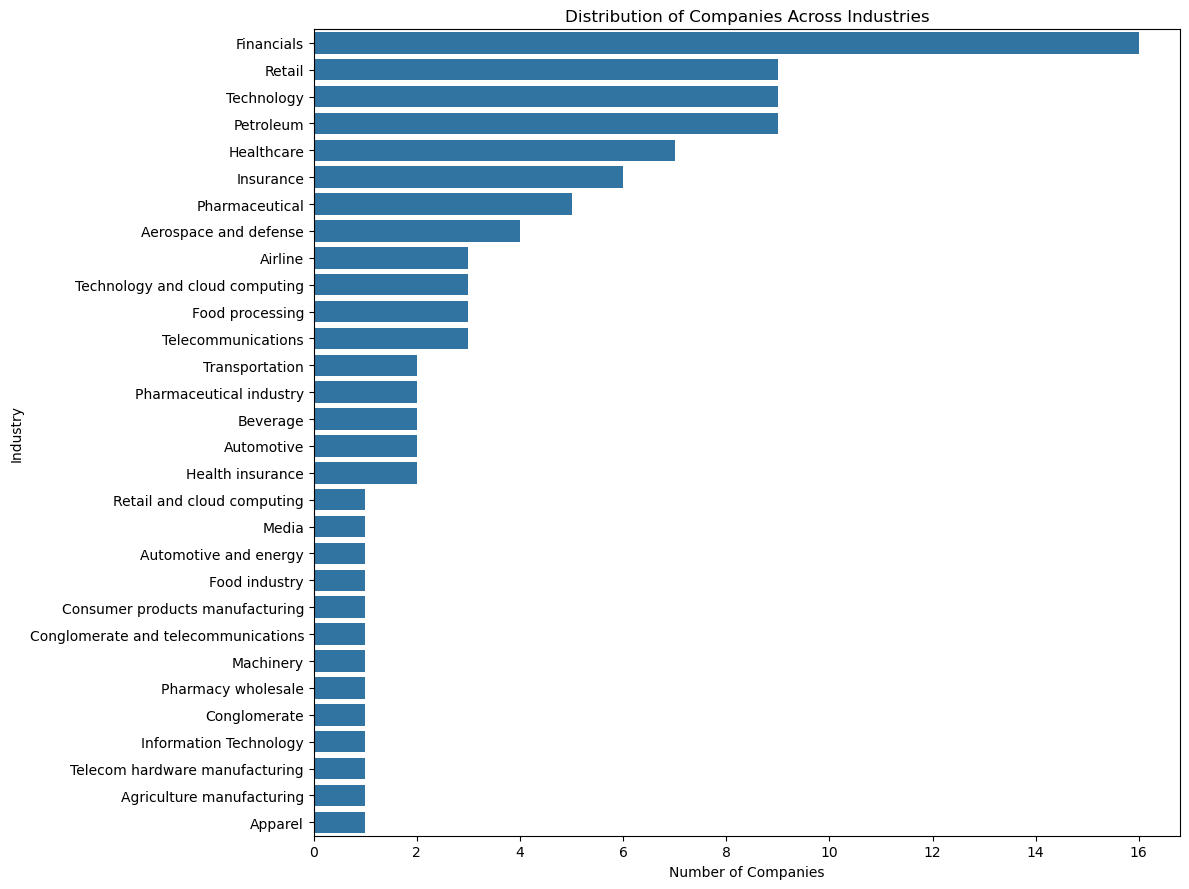

In [38]:
plt.figure(figsize=(12, 9))

industry_count = df['Industry'].value_counts()

sns.barplot(
    x=industry_count.values,
    y=industry_count.index
)

plt.title('Distribution of Companies Across Industries')
plt.xlabel('Number of Companies')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()

In [39]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [40]:
df['Revenue (INR Crores)'].describe()

count         100.00
mean    1,234,395.91
std     1,099,474.09
min       426,061.74
25%       537,316.13
50%       801,976.59
75%     1,408,549.15
max     6,441,437.12
Name: Revenue (INR Crores), dtype: float64

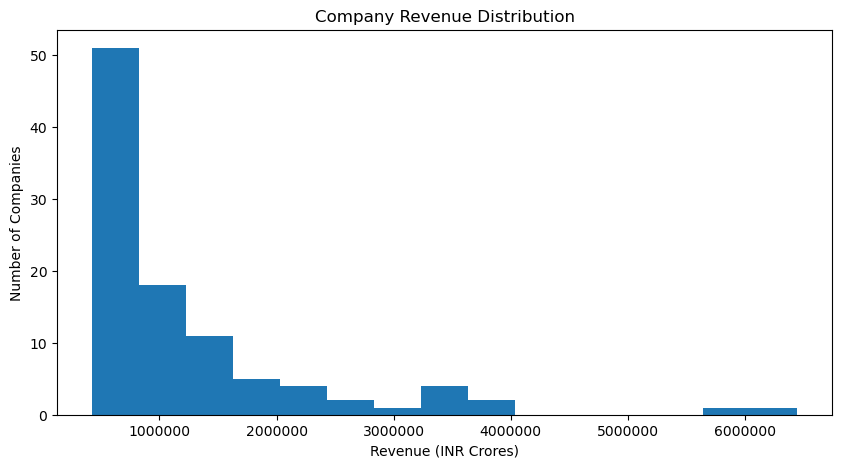

In [41]:
plt.figure(figsize=(10,5))

plt.hist(df['Revenue (INR Crores)'], bins=15)

plt.ticklabel_format(style='plain', axis='x')

plt.title('Company Revenue Distribution')
plt.xlabel('Revenue (INR Crores)')
plt.ylabel('Number of Companies')

plt.show()

In [42]:
df['Revenue growth'].describe()

count   100.00
mean      7.69
std      15.26
min     -15.60
25%       0.90
50%       5.05
75%      11.12
max     114.20
Name: Revenue growth, dtype: float64

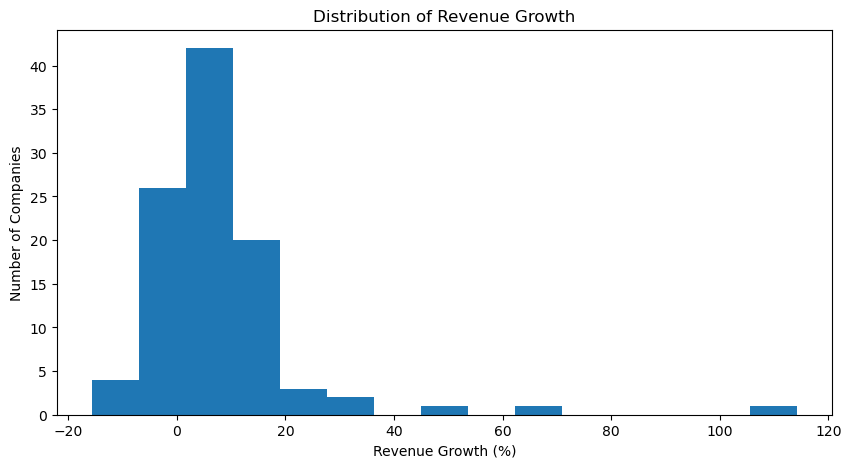

In [43]:
plt.figure(figsize=(10,5))

plt.hist(df['Revenue growth'], bins=15)

plt.title('Distribution of Revenue Growth')
plt.xlabel('Revenue Growth (%)')
plt.ylabel('Number of Companies')

plt.show()

In [44]:
df['Employees'].describe()

count         100.00
mean      161,977.67
std       268,276.16
min         4,200.00
25%        44,750.00
50%        85,700.00
75%       188,662.50
max     2,100,000.00
Name: Employees, dtype: float64

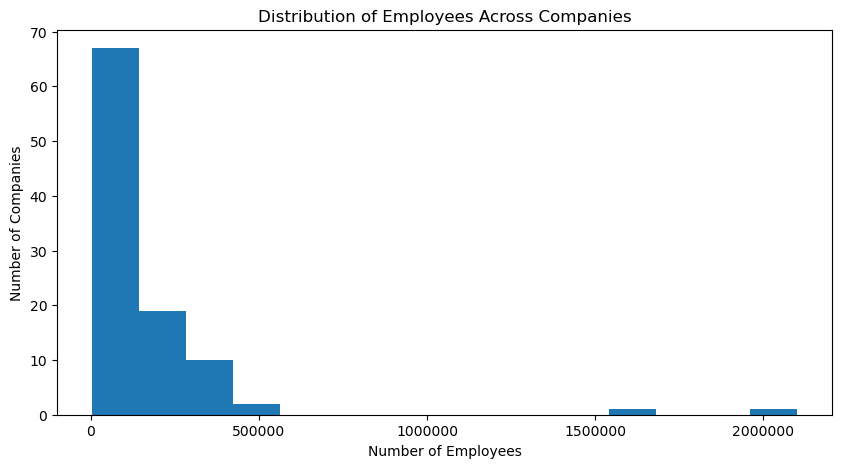

In [45]:
plt.figure(figsize=(10,5))

plt.hist(df['Employees'], bins=15)

plt.title('Distribution of Employees Across Companies')
plt.xlabel('Number of Employees')
plt.ylabel('Number of Companies')

plt.ticklabel_format(style='plain', axis='x')

plt.show()

Bivariate Analysis

Revenue vs Employees

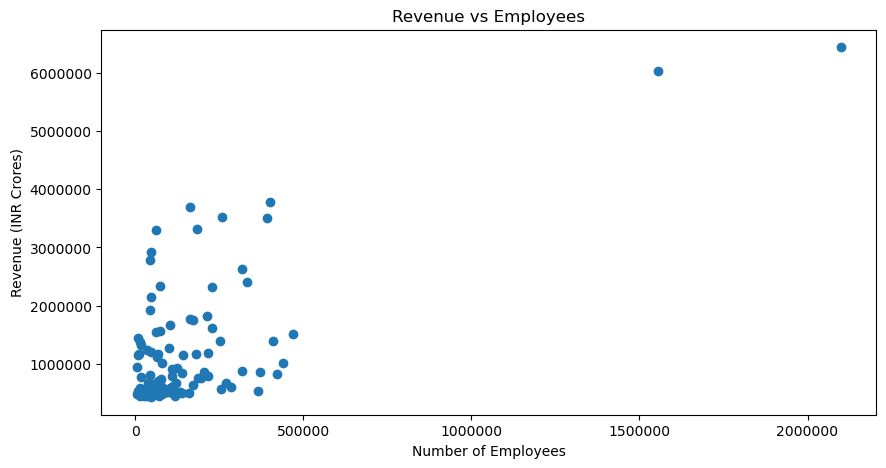

In [46]:
plt.figure(figsize=(10,5))

plt.scatter(df['Employees'], df['Revenue (INR Crores)'])

plt.title('Revenue vs Employees')
plt.xlabel('Number of Employees')
plt.ylabel('Revenue (INR Crores)')

plt.ticklabel_format(style='plain', axis='both')
plt.show()

Revenue vs Revenue Growth

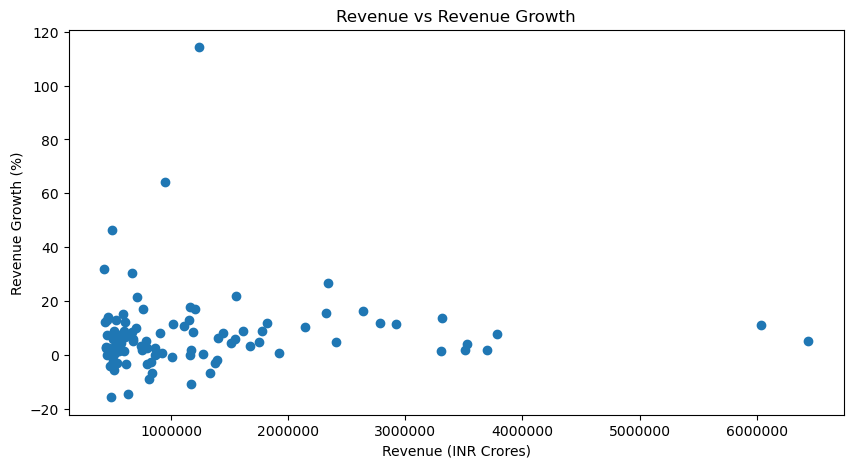

In [47]:
plt.figure(figsize=(10,5))

plt.scatter(df['Revenue (INR Crores)'], df['Revenue growth'])

plt.title('Revenue vs Revenue Growth')
plt.xlabel('Revenue (INR Crores)')
plt.ylabel('Revenue Growth (%)')

plt.ticklabel_format(style='plain', axis='x')
plt.show()

Industry-wise Analysis

Industry vs Average Revenue

In [48]:
industry_revenue = df.groupby('Industry')['Revenue (INR Crores)'].mean()

industry_revenue.sort_values(ascending=False)

Industry
Retail and cloud computing            6,034,454.18
Conglomerate                          3,513,384.75
Pharmacy wholesale                    2,780,558.18
Healthcare                            2,323,603.35
Technology and cloud computing        2,074,336.63
Automotive                            1,761,426.60
Health insurance                      1,725,709.42
Retail                                1,711,122.59
Petroleum                             1,269,802.44
Conglomerate and telecommunications   1,157,176.22
Financials                            1,108,071.60
Technology                            1,094,760.49
Telecommunications                      988,793.41
Automotive and energy                   924,049.71
Media                                   864,183.70
Transportation                          845,459.61
Food industry                           809,028.27
Consumer products manufacturing         794,924.90
Pharmaceutical                          730,529.92
Beverage              

In [49]:
pd.crosstab(df['Revenue Category'], df['Employee Size Category'])

Employee Size Category,Small Employer,Large Employer
Revenue Category,,
Low Revenue,89,0
Medium Revenue,9,0
High Revenue,0,2


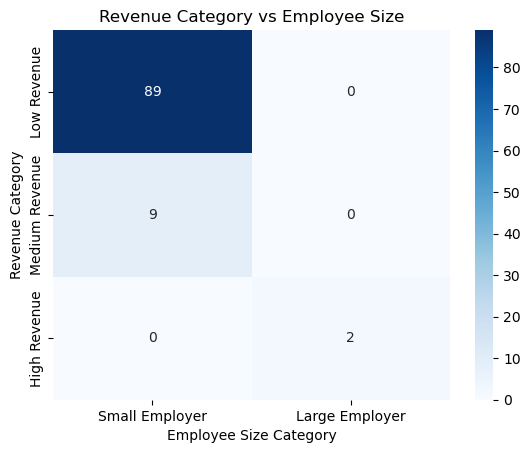

In [50]:
sns.heatmap(
    pd.crosstab(df['Revenue Category'], df['Employee Size Category']),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Revenue Category vs Employee Size')
plt.show()

In [51]:
df['Employees'].corr(df['Revenue (INR Crores)'])

np.float64(0.6902252639954786)

In [52]:
df['Revenue (INR Crores)'].corr(df['Revenue growth'])

np.float64(0.047706362176139584)

In [53]:
industry_growth = df.groupby('Industry')['Revenue growth'].mean()

industry_growth.sort_values(ascending=False)

Industry
Technology                             21.79
Health insurance                       18.65
Financials                             15.21
Pharmacy wholesale                     12.10
Insurance                              11.90
Retail and cloud computing             11.00
Technology and cloud computing         10.33
Pharmaceutical                          8.50
Pharmaceutical industry                 7.75
Healthcare                              7.44
Automotive                              7.05
Aerospace and defense                   5.15
Airline                                 5.03
Media                                   2.80
Consumer products manufacturing         2.50
Food processing                         2.20
Retail                                  2.16
Conglomerate                            1.90
Beverage                                1.65
Information Technology                  1.60
Telecommunications                      1.10
Automotive and energy                   0.90
A

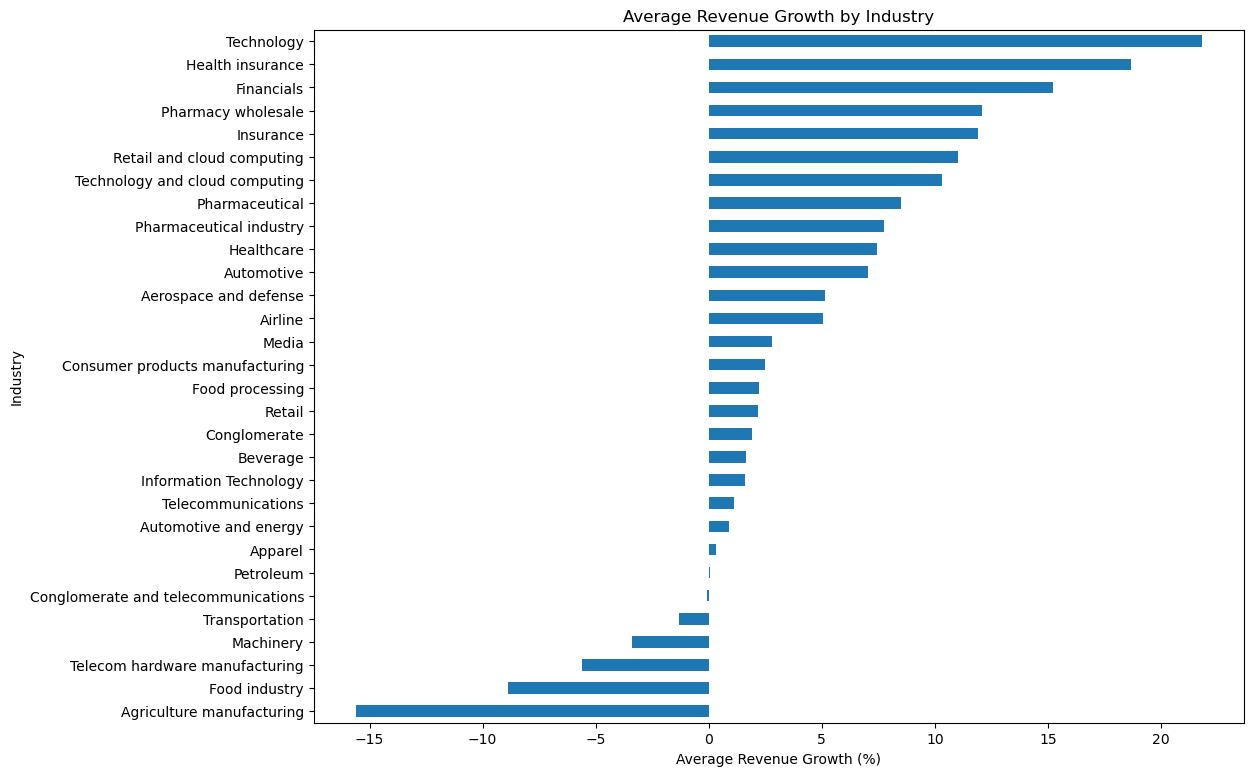

In [54]:
industry_growth.sort_values().plot(
    kind='barh',
    figsize=(12,9)
)

plt.title('Average Revenue Growth by Industry')
plt.xlabel('Average Revenue Growth (%)')
plt.ylabel('Industry')

plt.show()

In [55]:
industry_total_revenue = df.groupby('Industry')['Revenue (INR Crores)'].sum()

industry_total_revenue.sort_values(ascending=False)

Industry
Financials                            17,729,145.59
Healthcare                            16,265,223.45
Retail                                15,400,103.31
Petroleum                             11,428,221.92
Technology                             9,852,844.38
Technology and cloud computing         6,223,009.89
Retail and cloud computing             6,034,454.18
Pharmaceutical                         3,652,649.60
Automotive                             3,522,853.21
Conglomerate                           3,513,384.75
Health insurance                       3,451,418.84
Insurance                              3,287,276.81
Telecommunications                     2,966,380.24
Pharmacy wholesale                     2,780,558.18
Aerospace and defense                  2,516,235.89
Food processing                        1,767,262.81
Transportation                         1,690,919.22
Airline                                1,635,621.90
Beverage                               1,313,996.98
Pha

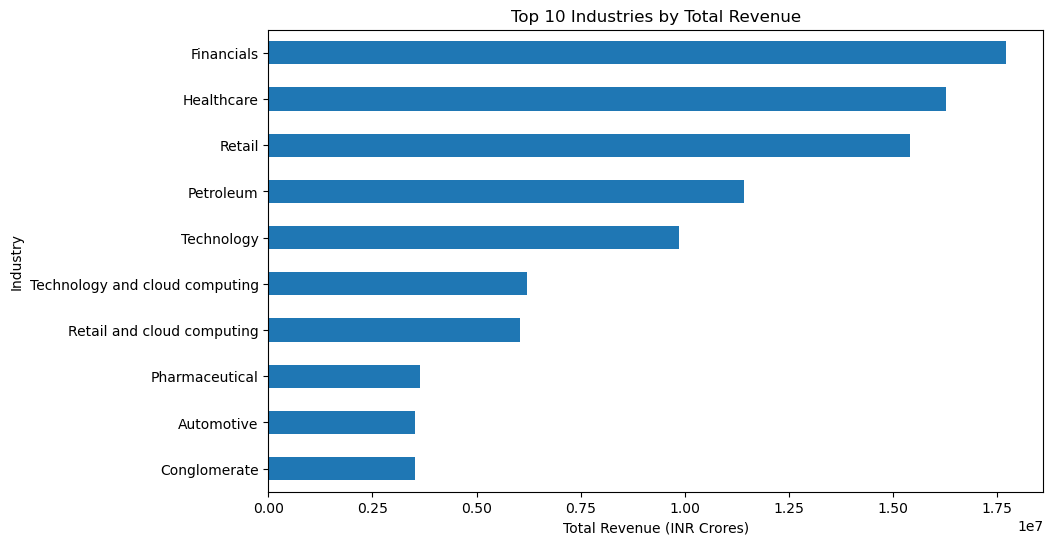

In [56]:
top_industries = industry_total_revenue.sort_values(
    ascending=False
).head(10)

top_industries.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Industries by Total Revenue')
plt.xlabel('Total Revenue (INR Crores)')
plt.ylabel('Industry')
plt.show()

In [57]:
industry_employees = df.groupby('Industry')['Employees'].sum()

industry_employees.sort_values(ascending=False)

Industry
Retail                                 4783250
Retail and cloud computing             1556000
Financials                             1439644
Healthcare                             1191090
Transportation                          794280
Technology                              771092
Technology and cloud computing          695823
Aerospace and defense                   596000
Pharmaceutical                          526700
Conglomerate                            392400
Beverage                                388700
Telecommunications                      376100
Airline                                 343600
Automotive                              333000
Food processing                         250815
Insurance                               248657
Media                                   205040
Petroleum                               187656
Pharmaceutical industry                 155000
Conglomerate and telecommunications     140990
Health insurance                        138078
Auto

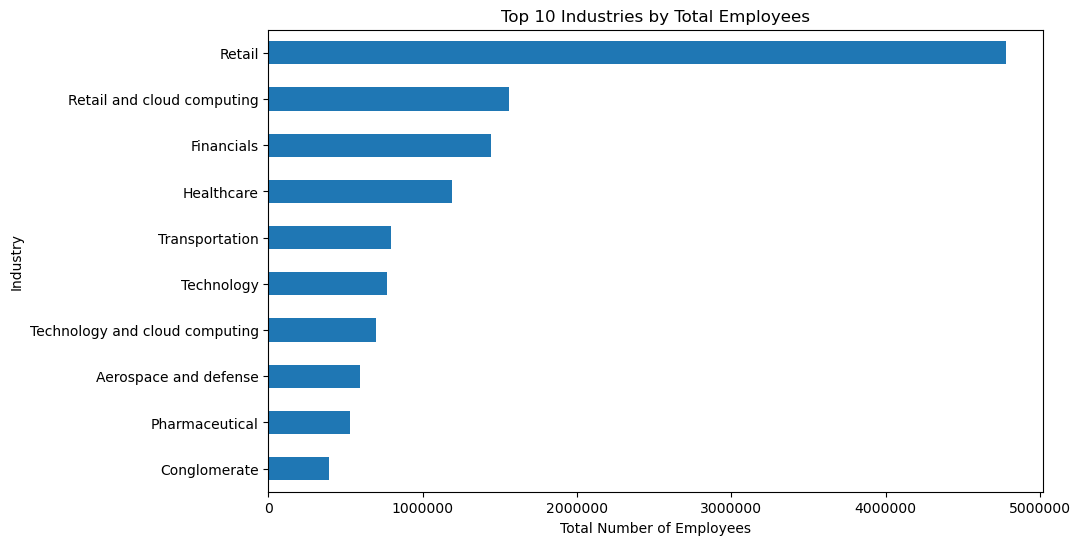

In [58]:
top_employee_industries = industry_employees.sort_values(
    ascending=False
).head(10)

top_employee_industries.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Industries by Total Employees')
plt.xlabel('Total Number of Employees')
plt.ylabel('Industry')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

Correlation Analysis


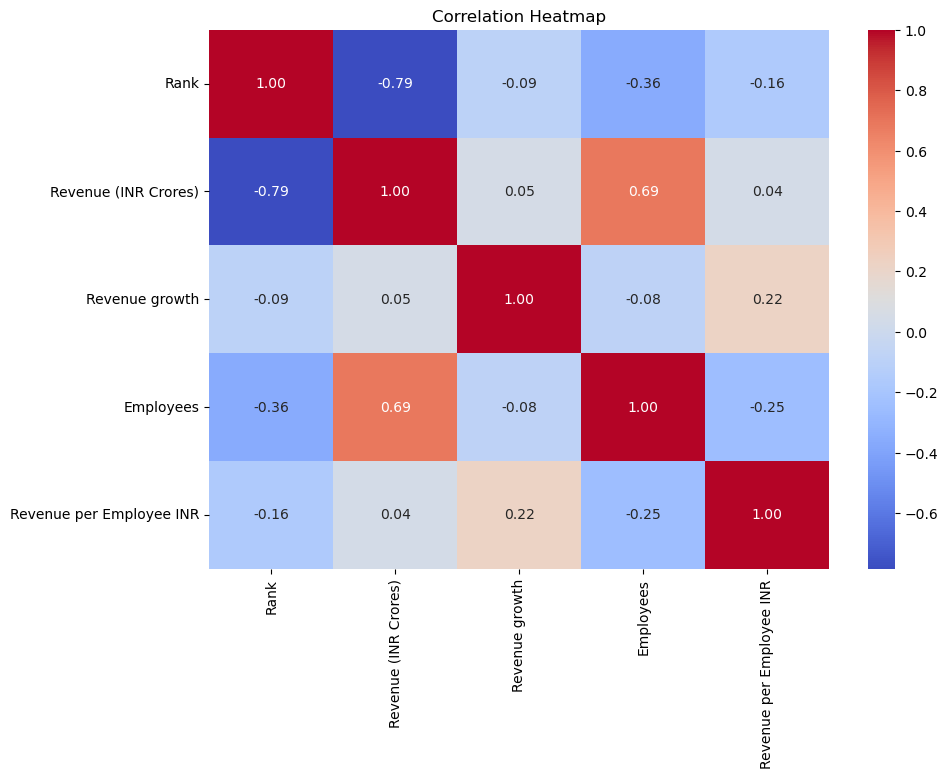

In [59]:
numeric_df = df.select_dtypes(include='number')

numeric_df = numeric_df.drop(
    columns=['Revenue Share (%)']
)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Outlier Detection

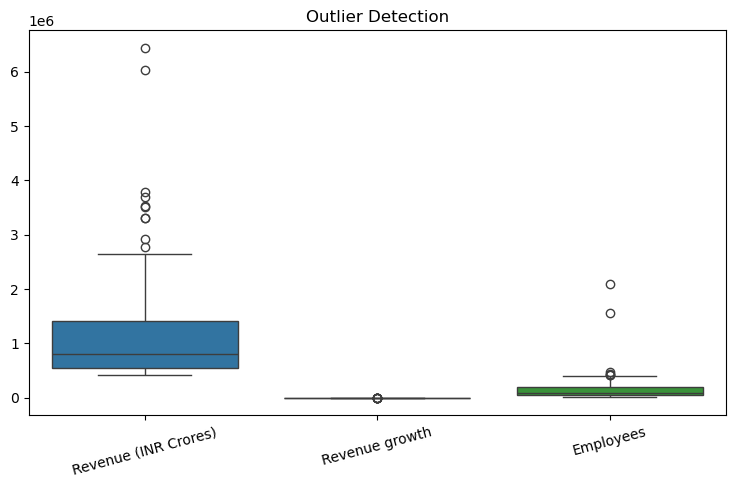

In [60]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df[
    ['Revenue (INR Crores)', 'Revenue growth', 'Employees']
])

plt.title('Outlier Detection')
plt.xticks(rotation=15)
plt.show()

IQR method 

In [61]:
columns = [
    'Revenue (INR Crores)',
    'Revenue growth',
    'Employees'
]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(col, ":", len(outliers), "outliers")

Revenue (INR Crores) : 10 outliers
Revenue growth : 8 outliers
Employees : 6 outliers


MULTIVARIATE ANALYSIS

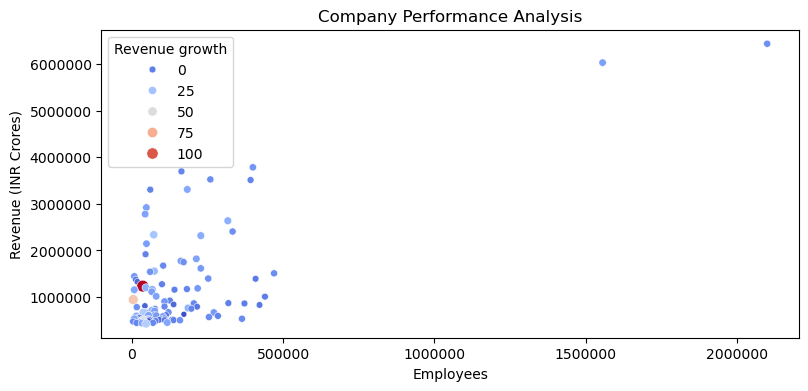

In [62]:
plt.figure(figsize=(9,4))

sns.scatterplot(
    data=df,
    x='Employees',
    y='Revenue (INR Crores)',
    hue='Revenue growth',
    palette='coolwarm',
    size='Revenue growth'
)

plt.title('Company Performance Analysis')
plt.ticklabel_format(style='plain', axis='both')
plt.show()

In [63]:
df.to_csv('Cleaned_Companies.csv', index=False)

Business Insights & Findings

# Business Insights & Findings

Based on the Exploratory Data Analysis (EDA) of 100 companies, 
the following insights were identified:

1. Industry Distribution:
   Financials is the most represented industry in the dataset,
   with 16 companies out of 100.

2. Revenue Distribution:
   Company revenue is right-skewed. A few companies generate
   significantly higher revenue than most other companies.

3. Revenue Growth:
   Average revenue growth is 7.69%. Some companies experienced
   negative growth, while a few recorded very high growth.

4. Employee Distribution:
   The average employee count is 161,978, while the median is
   85,700. This indicates that a few companies have very large
   workforces.

5. Revenue and Employees:
   Revenue and employee count have a positive correlation of
   approximately 0.69.

6. Revenue and Growth:
   Revenue and revenue growth have a very weak correlation
   of approximately 0.05.

7. Industry Growth:
   Technology recorded the highest average revenue growth
   among the industries, at 21.79%.

8. Outlier Detection:
   The IQR method identified 10 revenue outliers,
   8 revenue growth outliers, and 6 employee-count outliers.
   These observations were retained because they may represent
   genuine company values.

# Conclusion

This EDA helped identify patterns in company revenue,
revenue growth, employee distribution, and industry performance.

The analysis showed that companies with larger workforces
generally tend to generate higher revenue. However, higher
revenue does not necessarily mean higher revenue growth.

The findings can help understand company performance and
support further business analysis and decision-making.